# Setup

In [1]:
from pathlib import Path
import json
import time
import platform
import importlib.metadata

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    precision_recall_curve, roc_curve, confusion_matrix,
    ConfusionMatrixDisplay, precision_score, recall_score, f1_score,
    accuracy_score, balanced_accuracy_score
)
from sklearn.calibration import calibration_curve

PROJECT_DIR = Path('C:/Case Study Trees/AmazonEmployeeStudy')
SPLIT_DIR = PROJECT_DIR / 'data/splits'
MODEL_DIR = PROJECT_DIR / 'artifacts/models'
PREPROCESSOR_DIR = PROJECT_DIR / 'artifacts/preprocessors'
INPUT_INFO_DIR = PROJECT_DIR / 'artifacts/input_info'
VALIDATION_DIR = PROJECT_DIR / 'results/validation'
TEST_DIR = PROJECT_DIR / 'results/test'
PREDICTION_DIR = PROJECT_DIR / 'results/predictions'
FIGURE_DIR = PROJECT_DIR / 'results/figures'
for folder in [TEST_DIR, PREDICTION_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_THREADS = 4
TIMING_REPEATS = 7
TIMING_BATCH_SIZE = 1000
sns.set_theme(style='whitegrid')
model_keys = ['rf', 'xgb', 'lgb', 'cat']
model_names = {'rf': 'Random Forest', 'xgb': 'XGBoost',
               'lgb': 'LightGBM', 'cat': 'CatBoost'}

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()

versions = {'Python': platform.python_version(), 'Platform': platform.platform(),
            'CPU_Threads': N_THREADS}
for package in ['pandas', 'numpy', 'scikit-learn', 'xgboost', 'lightgbm',
                'catboost', 'optuna', 'joblib']:
    versions[package] = importlib.metadata.version(package)
(TEST_DIR / 'evaluation_environment.json').write_text(json.dumps(versions, indent=2))
display(pd.Series(versions, name='Version'))

Python                            3.11.16
Platform        Windows-10-10.0.26200-SP0
CPU_Threads                             4
pandas                              2.3.3
numpy                               2.3.5
scikit-learn                        1.9.1
xgboost                             3.2.0
lightgbm                            4.7.0
catboost                           1.2.10
optuna                              5.0.0
joblib                              1.6.0
Name: Version, dtype: object

# Load Models and Validation Results

In [2]:
models = {}
input_info = {}
for key in model_keys:
    models[key] = joblib.load(MODEL_DIR / f'amazon_{key}_tuned.joblib')
    input_info[key] = joblib.load(INPUT_INFO_DIR / f'amazon_{key}_input_info.joblib')
    if key in ['rf', 'xgb', 'lgb']:
        models[key].set_params(n_jobs=N_THREADS)

onehot_preprocessor = joblib.load(PREPROCESSOR_DIR / 'rf_onehot_preprocessor.joblib')
validation_results = pd.concat([
    pd.read_csv(VALIDATION_DIR / f'{key}_tuned_validation.csv')
    for key in model_keys
], ignore_index=True).sort_values('Validation_Log_Loss').reset_index(drop=True)
validation_winner = validation_results.loc[0, 'Model']
validation_results.to_csv(VALIDATION_DIR / 'all_tuned_validation_comparison.csv', index=False)
display(validation_results.round(6))
print('Primary selection metric: validation log loss (lower is better)')
print('Validation-selected model:', validation_winner)
print('Training times exclude preprocessing; tuning times are recorded search times.')

,Model,Representation,Validation_Log_Loss,Validation_ROC_AUC,Validation_AP_Approval,Validation_AP_Denial,Fit_Seconds,Tuning_Seconds,Completed_Trials,CPU_Threads
0,CatBoost,Native,0.139795,0.896240,0.990812,0.509308,89.949913,629.895850,13,4
1,LightGBM,Native,0.151810,0.862515,0.985253,0.449300,1.679199,600.017189,277,4
2,XGBoost,Native,0.154556,0.859079,0.985827,0.436466,13.838219,602.249659,40,4
3,Random Forest,One-hot,0.181329,0.800108,0.976842,0.311615,4.485610,602.573581,75,4


Primary selection metric: validation log loss (lower is better)
Validation-selected model: CatBoost
Training times exclude preprocessing; tuning times are recorded search times.


# Load Labelled Validation and Test Splits

In [3]:
feature_columns = input_info['rf']['feature_columns']
for key in model_keys:
    if input_info[key]['feature_columns'] != feature_columns:
        raise ValueError(f'Original input columns differ for {model_names[key]}')

# These are local labelled splits, not the unlabelled competition test file.
dtypes = {column: str for column in feature_columns}
valid_data = pd.read_csv(SPLIT_DIR / 'valid.csv', dtype=dtypes)
test_data = pd.read_csv(SPLIT_DIR / 'test.csv', dtype=dtypes)
train_ids = pd.read_csv(SPLIT_DIR / 'train.csv', usecols=['ROW_ID'])['ROW_ID']
assert set(train_ids).isdisjoint(valid_data['ROW_ID'])
assert set(train_ids).isdisjoint(test_data['ROW_ID'])
assert set(valid_data['ROW_ID']).isdisjoint(test_data['ROW_ID'])
assert valid_data['ROW_ID'].is_unique and test_data['ROW_ID'].is_unique

X_valid = valid_data[feature_columns].copy()
y_valid = valid_data['ACTION'].to_numpy()
X_test = test_data[feature_columns].copy()
y_test = test_data['ACTION'].to_numpy()
assert set(np.unique(y_valid)) == {0, 1}
assert set(np.unique(y_test)) == {0, 1}
print('Validation rows:', len(X_valid))
print('Test rows:', len(X_test))
print('ACTION=1: approval; ACTION=0: denial')
print('Test approval rate:', round(y_test.mean(), 4))
print('Test denial rate:', round(1-y_test.mean(), 4))

Validation rows: 4915
Test rows: 4916
ACTION=1: approval; ACTION=0: denial
Test approval rate: 0.942
Test denial rate: 0.058


# Model Input Preparation

In [4]:
def prepare_inputs(key, raw):
    info = input_info[key]
    data = raw[info['feature_columns']].copy()
    if key == 'rf':
        return onehot_preprocessor.transform(data)
    if key in ['xgb', 'lgb']:
        for column in info['categorical_columns']:
            category_type = pd.CategoricalDtype(
                categories=info['category_levels'][column]
            )
            data[column] = data[column].astype(category_type)
    else:
        for column in info['categorical_columns']:
            data[column] = data[column].fillna('Missing').astype(str)
    return data


def predict_probability(key, prepared):
    model = models[key]
    if key == 'cat':
        probabilities = model.predict_proba(prepared, thread_count=N_THREADS)
    else:
        probabilities = model.predict_proba(prepared)
    positive_column = list(model.classes_).index(1)
    return probabilities[:, positive_column]

print('Input preparation ready for all four models.')

Input preparation ready for all four models.


# Freeze Thresholds on Validation

In [5]:
thresholds = {}
validation_predictions = {}
threshold_records = []
for key in model_keys:
    prepared = prepare_inputs(key, X_valid)
    probabilities = predict_probability(key, prepared)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    actual_loss = log_loss(y_valid, probabilities)
    saved_loss = validation_results.loc[
        validation_results['Model'] == model_names[key], 'Validation_Log_Loss'
    ].iloc[0]
    if not np.isclose(actual_loss, saved_loss, atol=1e-5, rtol=0):
        raise ValueError(f'Validation mismatch for {model_names[key]}: '
                         f'loaded={actual_loss}, saved={saved_loss}')

    precision, recall, candidates = precision_recall_curve(y_valid, probabilities)
    scores = 2 * precision[:-1] * recall[:-1] / np.maximum(
        precision[:-1] + recall[:-1], 1e-15
    )
    threshold = float(candidates[np.argmax(scores)])
    thresholds[key] = threshold
    validation_predictions[key] = probabilities
    threshold_records.append({
        'Model': model_names[key], 'Approval_F1_Threshold': threshold,
        'Validation_F1_Approval': float(scores.max()),
        'Validation_Log_Loss_Checked': actual_loss
    })
    pd.DataFrame({'ROW_ID': valid_data['ROW_ID'], 'ACTION': y_valid,
                  'Approval_Probability': probabilities}).to_csv(
        PREDICTION_DIR / f'{key}_validation_predictions.csv', index=False
    )
threshold_table = pd.DataFrame(threshold_records)
threshold_table.to_csv(VALIDATION_DIR / 'frozen_thresholds.csv', index=False)
(TEST_DIR / 'frozen_selection.json').write_text(json.dumps({
    'Selection_Metric': 'Validation_Log_Loss',
    'Validation_Selected_Model': validation_winner,
    'Threshold_Objective': 'Validation F1 for ACTION=1 (approval)',
    'Thresholds': thresholds
}, indent=2))
display(threshold_table.round(6))
print('Thresholds frozen. No thresholds or parameters will be selected on test data.')

,Model,Approval_F1_Threshold,Validation_F1_Approval,Validation_Log_Loss_Checked
0,Random Forest,0.599200,0.971278,0.181329
1,XGBoost,0.458495,0.975263,0.154556
2,LightGBM,0.517602,0.974756,0.151810
3,CatBoost,0.519937,0.977299,0.139795


Thresholds frozen. No thresholds or parameters will be selected on test data.


# Final Test Metrics

In [6]:
test_predictions = {}
metric_records = []
for key in model_keys:
    probabilities = predict_probability(key, prepare_inputs(key, X_test))
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    predictions = (probabilities >= thresholds[key]).astype(int)
    test_predictions[key] = probabilities
    metric_records.append({
        'Model': model_names[key],
        'Representation': 'One-hot' if key == 'rf' else 'Native',
        'Test_Log_Loss': log_loss(y_test, probabilities),
        'Test_ROC_AUC': roc_auc_score(y_test, probabilities),
        'Test_AP_Approval': average_precision_score(y_test, probabilities),
        'Test_AP_Denial': average_precision_score(1-y_test, 1-probabilities),
        'Test_Brier': brier_score_loss(y_test, probabilities),
        'Test_Accuracy': accuracy_score(y_test, predictions),
        'Test_Balanced_Accuracy': balanced_accuracy_score(y_test, predictions),
        'Test_Precision_Approval': precision_score(y_test, predictions, zero_division=0),
        'Test_Recall_Approval': recall_score(y_test, predictions, zero_division=0),
        'Test_F1_Approval': f1_score(y_test, predictions, zero_division=0),
        'Test_Precision_Denial': precision_score(y_test, predictions, pos_label=0, zero_division=0),
        'Test_Recall_Denial': recall_score(y_test, predictions, pos_label=0, zero_division=0),
        'Test_F1_Denial': f1_score(y_test, predictions, pos_label=0, zero_division=0),
        'Approval_F1_Threshold': thresholds[key]
    })
    pd.DataFrame({'ROW_ID': test_data['ROW_ID'], 'ACTION': y_test,
                  'Approval_Probability': probabilities,
                  'Prediction': predictions}).to_csv(
        PREDICTION_DIR / f'{key}_test_predictions.csv', index=False
    )
test_results = pd.DataFrame(metric_records).sort_values('Test_Log_Loss').reset_index(drop=True)
test_results.to_csv(TEST_DIR / 'tuned_test_metrics.csv', index=False)
display(test_results.round(6))
print('AP is average precision, not trapezoidal PR-AUC.')
print('Classification metrics use validation-selected approval-F1 thresholds.')

,Model,Representation,Test_Log_Loss,Test_ROC_AUC,Test_AP_Approval,Test_AP_Denial,Test_Brier,Test_Accuracy,Test_Balanced_Accuracy,Test_Precision_Approval,Test_Recall_Approval,Test_F1_Approval,Test_Precision_Denial,Test_Recall_Denial,Test_F1_Denial,Approval_F1_Threshold
0,CatBoost,Native,0.142579,0.880942,0.988922,0.521190,0.037003,0.951383,0.656437,0.959607,0.990067,0.974599,0.666667,0.322807,0.434988,0.519937
1,LightGBM,Native,0.152650,0.860657,0.986557,0.478918,0.039567,0.951180,0.625047,0.955971,0.993954,0.974592,0.722772,0.256140,0.378238,0.517602
2,XGBoost,Native,0.158400,0.853604,0.985878,0.444337,0.041048,0.949146,0.614089,0.954744,0.993090,0.973539,0.676768,0.235088,0.348958,0.458495
3,Random Forest,One-hot,0.183605,0.802323,0.978517,0.323397,0.047082,0.942636,0.564534,0.949184,0.992226,0.970228,0.520000,0.136842,0.216667,0.599200


AP is average precision, not trapezoidal PR-AUC.
Classification metrics use validation-selected approval-F1 thresholds.


# Training and Inference Times

In [ ]:
batch = X_test.iloc[:min(TIMING_BATCH_SIZE, len(X_test))].copy()
timing_records = []
for key in model_keys:
    prepared_batch = prepare_inputs(key, batch)
    for _ in range(2):
        predict_probability(key, prepared_batch)
        predict_probability(key, prepare_inputs(key, batch))
    model_times = []
    pipeline_times = []
    for _ in range(TIMING_REPEATS):
        start = time.perf_counter()
        predict_probability(key, prepared_batch)
        model_times.append(time.perf_counter() - start)
        start = time.perf_counter()
        predict_probability(key, prepare_inputs(key, batch))
        pipeline_times.append(time.perf_counter() - start)
    scale = 1000 / len(batch)
    timing_records.append({
        'Model': model_names[key], 'Batch_Rows': len(batch),
        'Timing_Repeats': TIMING_REPEATS, 'CPU_Threads': N_THREADS,
        'Model_Seconds_Per_1000': np.median(model_times) * scale,
        'Pipeline_Seconds_Per_1000': np.median(pipeline_times) * scale,
        'Pipeline_P25_Per_1000': np.percentile(pipeline_times, 25) * scale,
        'Pipeline_P75_Per_1000': np.percentile(pipeline_times, 75) * scale,
        'Model_File_MiB': (MODEL_DIR / f'amazon_{key}_tuned.joblib').stat().st_size / 1024**2
    })
timing_results = pd.DataFrame(timing_records)
timing_results = timing_results.merge(
    validation_results[['Model', 'Fit_Seconds', 'Tuning_Seconds', 'Completed_Trials']],
    on='Model', validate='one_to_one'
)
timing_results.to_csv(TEST_DIR / 'training_and_inference_times.csv', index=False)
display(timing_results.round(6))

,Model,Batch_Rows,Timing_Repeats,CPU_Threads,Model_Seconds_Per_1000,Pipeline_Seconds_Per_1000,Pipeline_P25_Per_1000,Pipeline_P75_Per_1000,Model_File_MiB,Fit_Seconds,Tuning_Seconds,Completed_Trials
0,Random Forest,1000,7,4,0.050544,0.100755,0.100668,0.101510,1.760873,4.485610,602.573581,75
1,XGBoost,1000,7,4,0.026279,0.039224,0.039137,0.041976,32.077237,13.838219,602.249659,40
2,LightGBM,1000,7,4,0.024949,0.043280,0.041071,0.044508,1.713886,1.679199,600.017189,277
3,CatBoost,1000,7,4,0.010469,0.017234,0.016285,0.017941,15.430433,89.949913,629.895850,13


# Winners

In [20]:
comparison = test_results.merge(
    timing_results.drop(columns=['CPU_Threads']), on='Model', validate='one_to_one'
)
comparison.to_csv(TEST_DIR / 'final_comparison.csv', index=False)
winner_records = [
    {'Category': 'Validation-selected model', 'Winner': validation_winner},
    {'Category': 'Lowest observed test log loss', 'Winner': test_results.loc[test_results['Test_Log_Loss'].idxmin(), 'Model']},
    {'Category': 'Highest test ROC-AUC', 'Winner': test_results.loc[test_results['Test_ROC_AUC'].idxmax(), 'Model']},
    {'Category': 'Highest test denial AP', 'Winner': test_results.loc[test_results['Test_AP_Denial'].idxmax(), 'Model']},
    {'Category': 'Fastest final training', 'Winner': timing_results.loc[timing_results['Fit_Seconds'].idxmin(), 'Model']},
    {'Category': 'Fastest pipeline inference', 'Winner': timing_results.loc[timing_results['Pipeline_Seconds_Per_1000'].idxmin(), 'Model']}
]
winners = pd.DataFrame(winner_records)
winners.to_csv(TEST_DIR / 'winners.csv', index=False)
display(winners)
display(comparison[['Model', 'Test_Log_Loss', 'Test_ROC_AUC', 'Test_AP_Denial',
                    'Fit_Seconds', 'Tuning_Seconds', 'Pipeline_Seconds_Per_1000',
                    'Completed_Trials']].round(6))
print('Primary metric: log loss. Other winners describe different trade-offs.')

,Category,Winner
0,Validation-selected model,CatBoost
1,Lowest observed test log loss,CatBoost
2,Highest test ROC-AUC,CatBoost
3,Highest test denial AP,CatBoost
4,Fastest final training,LightGBM
5,Fastest pipeline inference,CatBoost


,Model,Test_Log_Loss,Test_ROC_AUC,Test_AP_Denial,Fit_Seconds,Tuning_Seconds,Pipeline_Seconds_Per_1000,Completed_Trials
0,CatBoost,0.142579,0.880942,0.521190,89.949913,629.895850,0.019897,13
1,LightGBM,0.152650,0.860657,0.478918,1.679199,600.017189,0.048881,277
2,XGBoost,0.158400,0.853604,0.444337,13.838219,602.249659,0.047578,40
3,Random Forest,0.183605,0.802323,0.323397,4.485610,602.573581,0.108524,75


Primary metric: log loss. Other winners describe different trade-offs.


# Metric Comparison

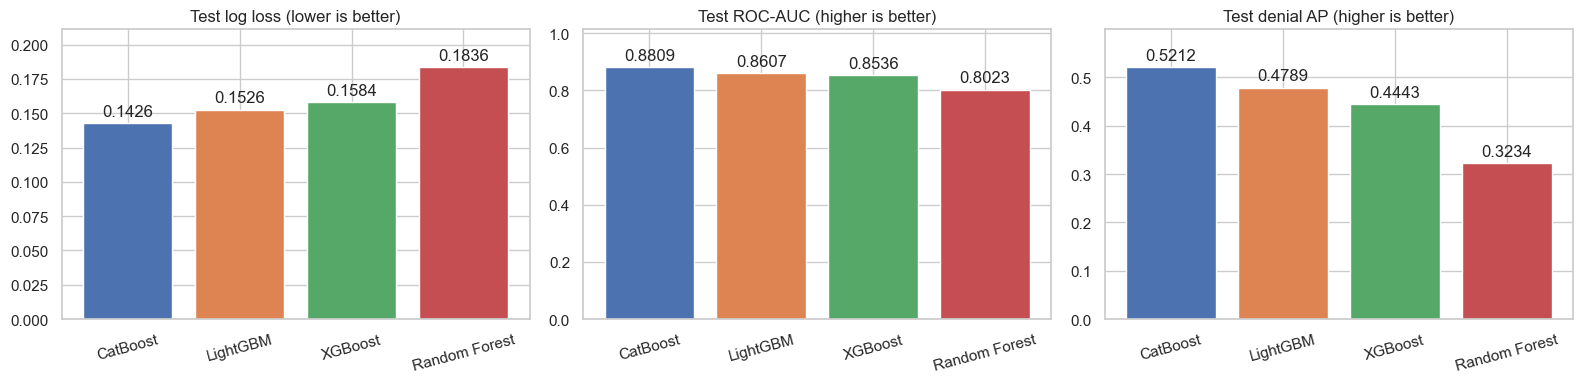

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, title in zip(axes,
    ['Test_Log_Loss', 'Test_ROC_AUC', 'Test_AP_Denial'],
    ['Test log loss (lower is better)', 'Test ROC-AUC (higher is better)',
     'Test denial AP (higher is better)']):
    bars = ax.bar(test_results['Model'], test_results[metric], color=sns.color_palette('deep', 4))
    ax.bar_label(bars, fmt='%.4f', padding=3)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=15)
    ax.set_ylim(0, test_results[metric].max() * 1.15)
save_plot('01_test_metric_comparison.png')

# ROC and Precision–Recall Curves

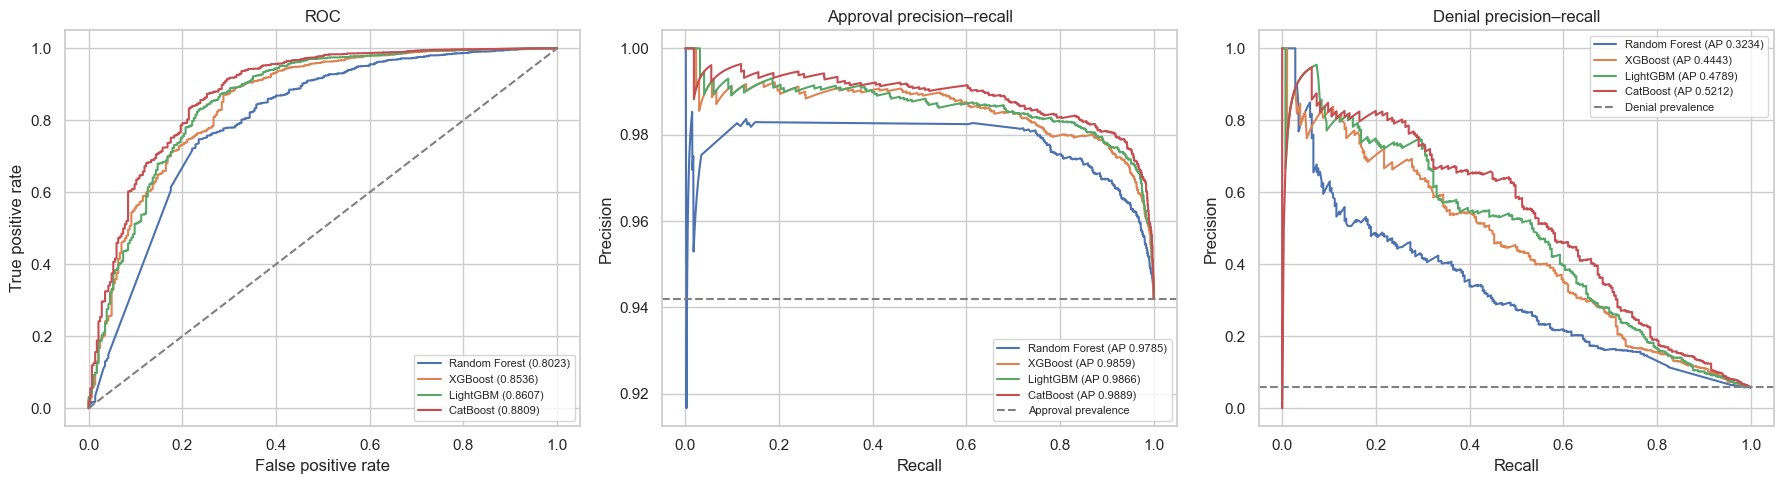

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for key in model_keys:
    p = test_predictions[key]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f'{model_names[key]} ({roc_auc_score(y_test, p):.4f})')
    precision, recall, _ = precision_recall_curve(y_test, p)
    axes[1].plot(recall, precision, label=f'{model_names[key]} (AP {average_precision_score(y_test, p):.4f})')
    precision, recall, _ = precision_recall_curve(1-y_test, 1-p)
    axes[2].plot(recall, precision, label=f'{model_names[key]} (AP {average_precision_score(1-y_test, 1-p):.4f})')
axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[1].axhline(y_test.mean(), linestyle='--', color='grey', label='Approval prevalence')
axes[2].axhline(1-y_test.mean(), linestyle='--', color='grey', label='Denial prevalence')
for ax, title, xlabel, ylabel in zip(axes,
    ['ROC', 'Approval precision–recall', 'Denial precision–recall'],
    ['False positive rate', 'Recall', 'Recall'], ['True positive rate', 'Precision', 'Precision']):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend(fontsize=8)
save_plot('02_roc_and_precision_recall.png')

# Confusion Matrices

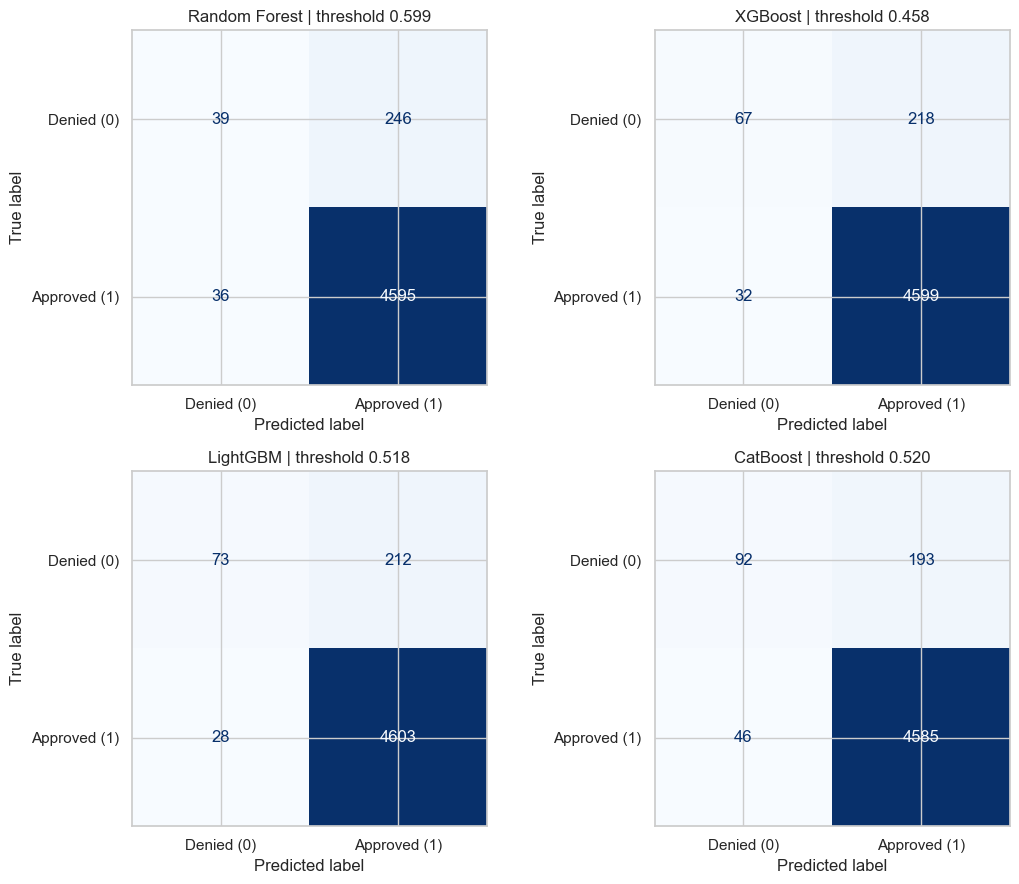

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, key in zip(axes.flat, model_keys):
    predictions = (test_predictions[key] >= thresholds[key]).astype(int)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=['Denied (0)', 'Approved (1)']).plot(
        ax=ax, colorbar=False, cmap='Blues', values_format='d'
    )
    ax.set_title(f'{model_names[key]} | threshold {thresholds[key]:.3f}')
save_plot('03_confusion_matrices.png')

# Probability Calibration

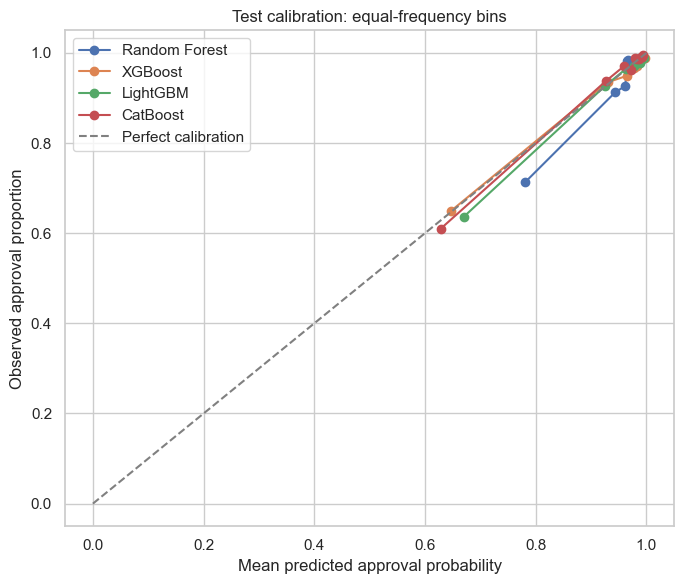

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
for key in model_keys:
    observed, predicted = calibration_curve(y_test, test_predictions[key], n_bins=10, strategy='quantile')
    ax.plot(predicted, observed, marker='o', label=model_names[key])
ax.plot([0, 1], [0, 1], '--', color='grey', label='Perfect calibration')
ax.set(xlabel='Mean predicted approval probability', ylabel='Observed approval proportion',
       title='Test calibration: equal-frequency bins')
ax.legend()
save_plot('04_calibration.png')

# Time and Model Size Graphs

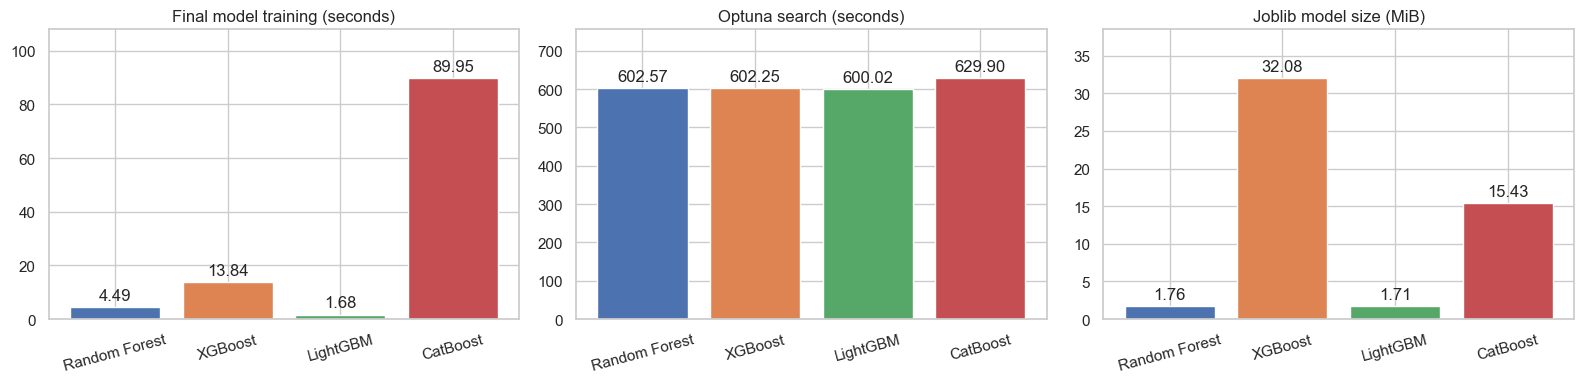

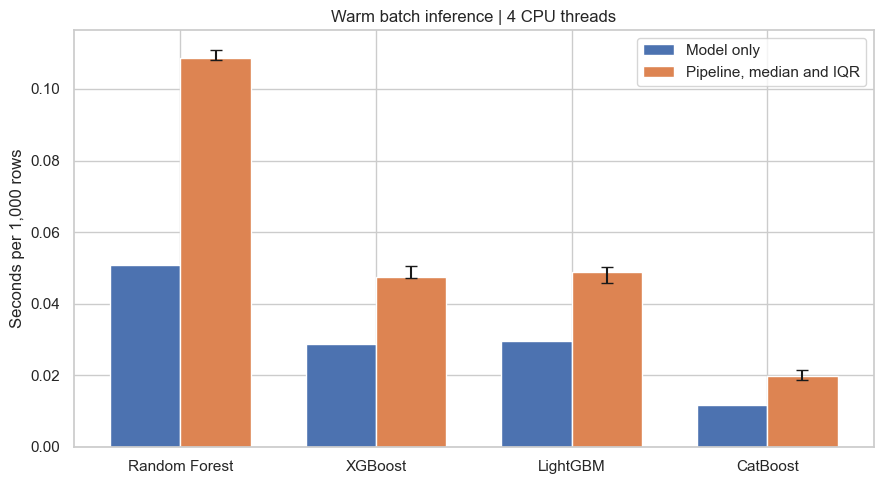

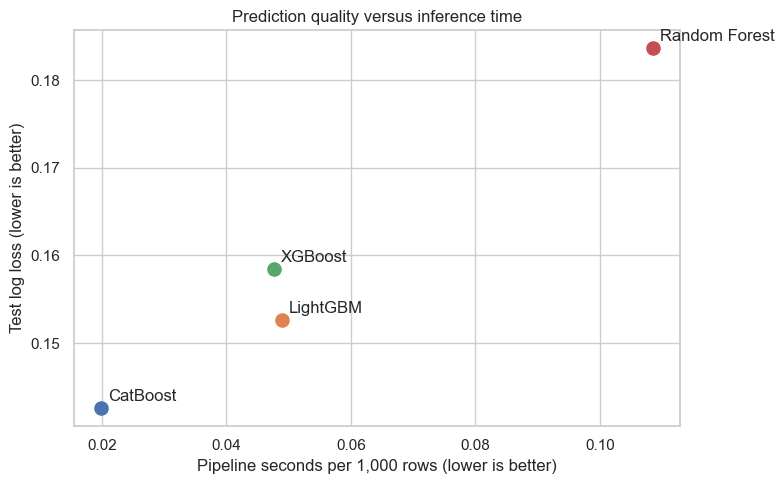

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column, title in zip(axes,
    ['Fit_Seconds', 'Tuning_Seconds', 'Model_File_MiB'],
    ['Final model training (seconds)', 'Optuna search (seconds)', 'Joblib model size (MiB)']):
    bars = ax.bar(timing_results['Model'], timing_results[column], color=sns.color_palette('deep', 4))
    ax.bar_label(bars, fmt='%.2f', padding=3)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=15)
    ax.set_ylim(0, timing_results[column].max() * 1.2)
save_plot('05_training_tuning_and_size.png')

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(timing_results))
ax.bar(x-0.18, timing_results['Model_Seconds_Per_1000'], width=0.36, label='Model only')
values = timing_results['Pipeline_Seconds_Per_1000'].to_numpy()
errors = np.vstack([
    values-timing_results['Pipeline_P25_Per_1000'].to_numpy(),
    timing_results['Pipeline_P75_Per_1000'].to_numpy()-values
])
ax.bar(x+0.18, values, width=0.36, yerr=errors, capsize=4, label='Pipeline, median and IQR')
ax.set_xticks(x, timing_results['Model'])
ax.set(ylabel='Seconds per 1,000 rows', title=f'Warm batch inference | {N_THREADS} CPU threads')
ax.legend()
save_plot('06_inference_times.png')

fig, ax = plt.subplots(figsize=(8, 5))
for _, row in comparison.iterrows():
    ax.scatter(row['Pipeline_Seconds_Per_1000'], row['Test_Log_Loss'], s=90)
    ax.annotate(row['Model'], (row['Pipeline_Seconds_Per_1000'], row['Test_Log_Loss']),
                xytext=(5, 5), textcoords='offset points')
ax.set(xlabel='Pipeline seconds per 1,000 rows (lower is better)',
       ylabel='Test log loss (lower is better)', title='Prediction quality versus inference time')
save_plot('07_quality_vs_inference.png')

# Optuna Progress

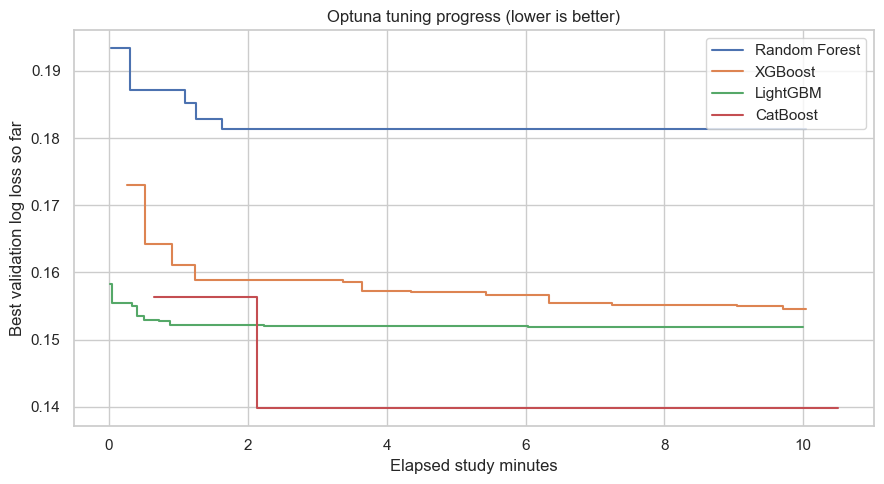

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
for key in model_keys:
    trials = pd.read_csv(VALIDATION_DIR / f'{key}_optuna_trials.csv')
    for column in ['datetime_start', 'datetime_complete']:
        trials[column] = pd.to_datetime(trials[column])
    origin = trials['datetime_start'].min()
    completed = trials[(trials['state'] == 'COMPLETE') & trials['value'].notna()].copy()
    completed = completed.sort_values('datetime_complete')
    completed['Elapsed_Minutes'] = (completed['datetime_complete']-origin).dt.total_seconds()/60
    ax.step(completed['Elapsed_Minutes'], completed['value'].cummin(),
            where='post', label=model_names[key])
ax.set(xlabel='Elapsed study minutes', ylabel='Best validation log loss so far',
       title='Optuna tuning progress (lower is better)')
ax.legend()
save_plot('08_optuna_progress.png')

# Paired Bootstrap Uncertainty

,Comparison,Log_Loss_Difference,CI_Lower,CI_Upper,Interpretation
0,Random Forest minus XGBoost,0.025205,0.017447,0.033490,Second model lower loss
1,Random Forest minus LightGBM,0.030955,0.023931,0.037464,Second model lower loss
2,Random Forest minus CatBoost,0.041025,0.032921,0.048984,Second model lower loss
3,XGBoost minus LightGBM,0.005750,0.001352,0.010644,Second model lower loss
4,XGBoost minus CatBoost,0.015821,0.009966,0.022028,Second model lower loss
5,LightGBM minus CatBoost,0.010071,0.005151,0.015814,Second model lower loss


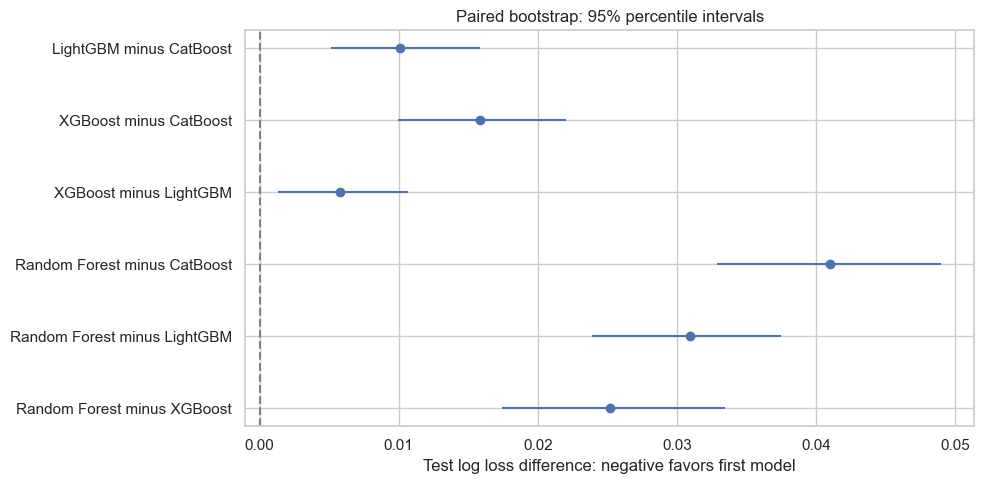

In [18]:
N_BOOTSTRAPS = 1000
rng = np.random.default_rng(RANDOM_STATE)
class_rows = [np.flatnonzero(y_test == label) for label in [0, 1]]
row_losses = {}
for key in model_keys:
    p = np.clip(test_predictions[key], 1e-15, 1-1e-15)
    row_losses[key] = -(y_test*np.log(p) + (1-y_test)*np.log1p(-p))
bootstrap_records = []
for i, first in enumerate(model_keys):
    for second in model_keys[i+1:]:
        differences = row_losses[first] - row_losses[second]
        samples = np.empty(N_BOOTSTRAPS)
        for repeat in range(N_BOOTSTRAPS):
            rows = np.concatenate([rng.choice(group, len(group), replace=True) for group in class_rows])
            samples[repeat] = differences[rows].mean()
        low, high = np.percentile(samples, [2.5, 97.5])
        bootstrap_records.append({
            'Comparison': f'{model_names[first]} minus {model_names[second]}',
            'Log_Loss_Difference': differences.mean(), 'CI_Lower': low, 'CI_Upper': high,
            'Interpretation': ('First model lower loss' if high < 0 else
                               'Second model lower loss' if low > 0 else 'Interval includes zero')
        })
bootstrap_results = pd.DataFrame(bootstrap_records)
bootstrap_results.to_csv(TEST_DIR / 'paired_bootstrap_logloss.csv', index=False)
display(bootstrap_results.round(6))
fig, ax = plt.subplots(figsize=(10, 5))
values = bootstrap_results['Log_Loss_Difference'].to_numpy()
# Draw interval endpoints directly; percentile intervals need not contain the point estimate.
y = np.arange(len(bootstrap_results))
ax.hlines(y, bootstrap_results['CI_Lower'], bootstrap_results['CI_Upper'])
ax.scatter(values, y)
ax.axvline(0, color='grey', linestyle='--')
ax.set_yticks(y, bootstrap_results['Comparison'])
ax.set(xlabel='Test log loss difference: negative favors first model',
       title='Paired bootstrap: 95% percentile intervals')
save_plot('09_paired_bootstrap.png')

# Feature Importance on a Shared Scale

Permutation importance: Random Forest
Permutation importance: XGBoost
Permutation importance: LightGBM
Permutation importance: CatBoost


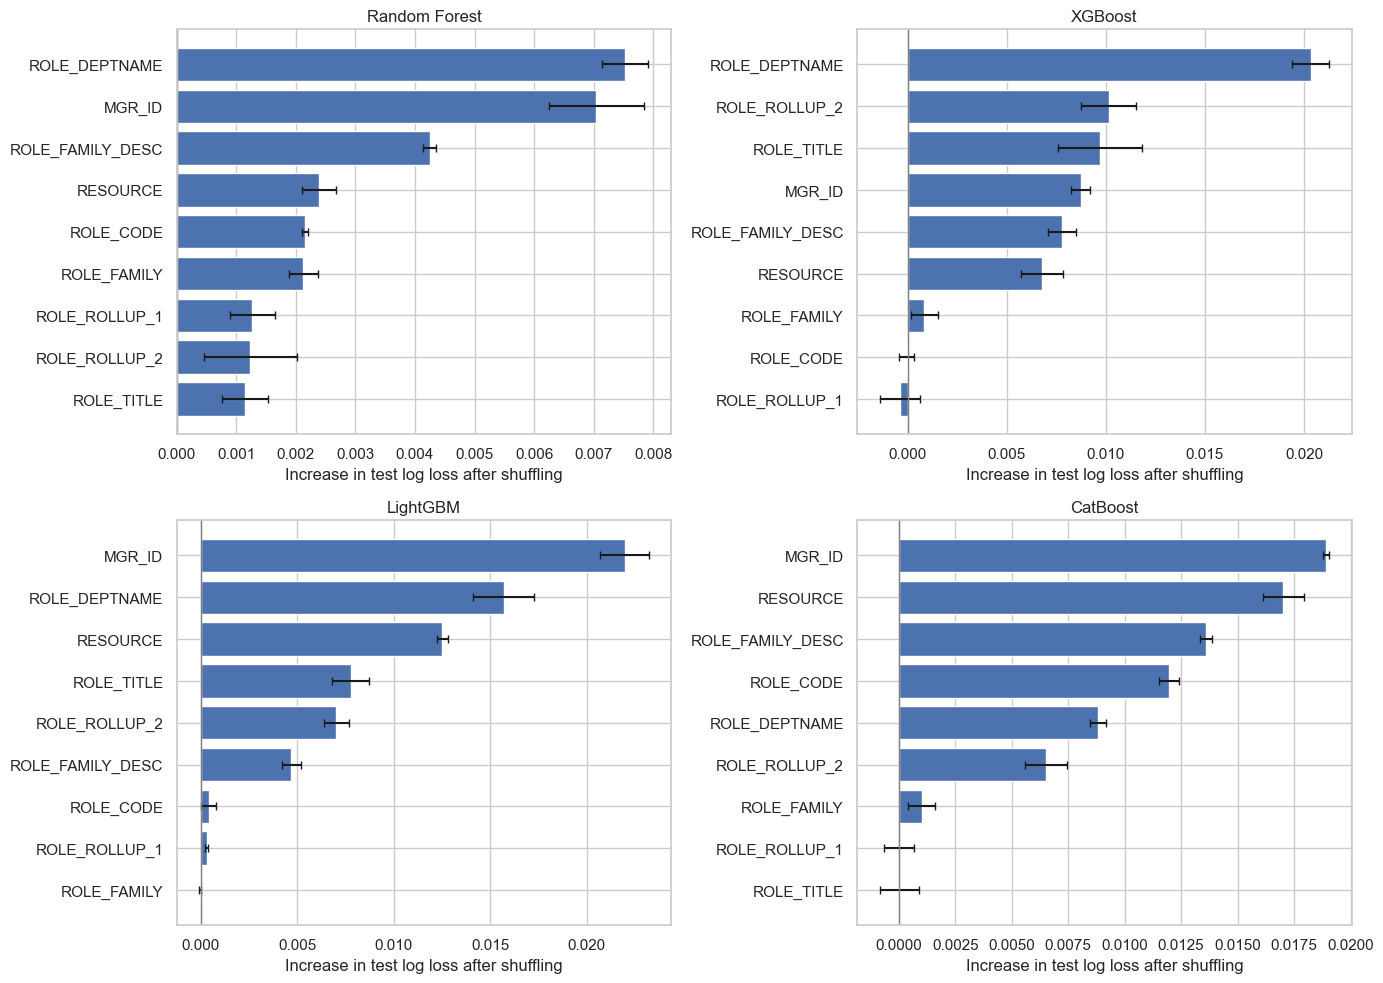

In [17]:
IMPORTANCE_ROWS = min(2000, len(X_test))
IMPORTANCE_REPEATS = 3
importance_sample = X_test.sample(n=IMPORTANCE_ROWS, random_state=RANDOM_STATE)
importance_target = test_data.loc[importance_sample.index, 'ACTION'].to_numpy()
importance_records = []
for key in model_keys:
    print('Permutation importance:', model_names[key], flush=True)
    baseline = log_loss(importance_target,
                       predict_probability(key, prepare_inputs(key, importance_sample)))
    rng = np.random.default_rng(RANDOM_STATE)
    for column in feature_columns:
        changes = []
        for repeat in range(IMPORTANCE_REPEATS):
            shuffled = importance_sample.copy()
            shuffled[column] = rng.permutation(shuffled[column].to_numpy())
            p = predict_probability(key, prepare_inputs(key, shuffled))
            changes.append(log_loss(importance_target, p)-baseline)
        importance_records.append({
            'Model': model_names[key], 'Feature': column,
            'Log_Loss_Increase': np.mean(changes),
            'Repeat_SD': np.std(changes), 'Sample_Rows': IMPORTANCE_ROWS
        })
importance_results = pd.DataFrame(importance_records)
importance_results.to_csv(TEST_DIR / 'permutation_importance.csv', index=False)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, key in zip(axes.flat, model_keys):
    rows = importance_results[importance_results['Model'] == model_names[key]].sort_values('Log_Loss_Increase')
    ax.barh(rows['Feature'], rows['Log_Loss_Increase'], xerr=rows['Repeat_SD'], capsize=3)
    ax.axvline(0, color='grey', linewidth=1)
    ax.set(title=model_names[key], xlabel='Increase in test log loss after shuffling')
save_plot('10_permutation_importance.png')

# Final Results

In [23]:
display(winners)
display(comparison[['Model', 'Test_Log_Loss', 'Test_ROC_AUC', 'Test_AP_Approval',
                    'Test_AP_Denial', 'Test_Brier', 'Fit_Seconds', 'Tuning_Seconds',
                    'Pipeline_Seconds_Per_1000', 'Completed_Trials']].round(6))
print('Validation-selected model:', validation_winner)
print('Observed lowest test log loss:', test_results.iloc[0]['Model'])
print('Check paired intervals before claiming a clear quality advantage.')
print('This compares tuned pipelines on one split, not categorical encoding in isolation.')
print('Total recorded tuning seconds:', round(timing_results['Tuning_Seconds'].sum(), 2))
print('Total final-fit seconds:', round(timing_results['Fit_Seconds'].sum(), 2))

,Category,Winner
0,Validation-selected model,CatBoost
1,Lowest observed test log loss,CatBoost
2,Highest test ROC-AUC,CatBoost
3,Highest test denial AP,CatBoost
4,Fastest final training,LightGBM
5,Fastest pipeline inference,CatBoost


,Model,Test_Log_Loss,Test_ROC_AUC,Test_AP_Approval,Test_AP_Denial,Test_Brier,Fit_Seconds,Tuning_Seconds,Pipeline_Seconds_Per_1000,Completed_Trials
0,CatBoost,0.142579,0.880942,0.988922,0.521190,0.037003,89.949913,629.895850,0.019897,13
1,LightGBM,0.152650,0.860657,0.986557,0.478918,0.039567,1.679199,600.017189,0.048881,277
2,XGBoost,0.158400,0.853604,0.985878,0.444337,0.041048,13.838219,602.249659,0.047578,40
3,Random Forest,0.183605,0.802323,0.978517,0.323397,0.047082,4.485610,602.573581,0.108524,75


Validation-selected model: CatBoost
Observed lowest test log loss: CatBoost
Check paired intervals before claiming a clear quality advantage.
This compares tuned pipelines on one split, not categorical encoding in isolation.
Total recorded tuning seconds: 2434.74
Total final-fit seconds: 109.95
